# Feux de forêts en Nouvelle-Aquitaine

Objectif : détecter et prédire les départs de feux de forêt en Nouvelle-Aquitaine.

> ⚙️ `UTILISER_API = False` (cellule d'imports) : le notebook ne lit que les `.csv` présents dans `data/`, sans aucun appel réseau.

> 📥 **Tout télécharger une fois pour toutes** : `python pipeline/telecharger_sources.py`, lancé depuis la racine du dépôt. Le script récupère les sources accessibles par API (communes, toutes les saisons de la Météo des forêts, Open-Meteo, FIRMS) et les enregistre dans `data/`. Il est reprenable et gère les limites de requêtes. Ensuite, chaque section de ce notebook lit son fichier local au lieu d'appeler l'API.

Ce notebook **télécharge et explore** les sources. L'entrepôt (couches bronze, silver et gold) est construit à partir des mêmes fichiers par `pipeline/pipeline_medaillon.py`, que lance la dernière section. Le modèle de données est décrit dans `docs/entrepot/04-modele-uml.md`, et les sources dans `docs/sources.md`.

## Les 5 sources du projet
Une source par rôle, sans doublon :

| # | Source | Rôle | Contenu | Accès | Fichier `data/` | Table gold |
|---|---|---|---|---|---|---|
| 1 | [BDIFF](https://bdiff.agriculture.gouv.fr/incendies) | **Cible** : les feux à prédire | Incendies 2006-2025 (date, commune, surfaces, cause) | Export CSV manuel | `incendies.csv` | `fait_incendie` |
| 2 | [Archives Météo des forêts](https://www.data.gouv.fr/datasets/archives-de-la-meteo-des-forets) (Météo-France) | **Indice à évaluer** (seuil de déclenchement) | Niveau de danger 1 à 4, J+1 et J+2, par département (depuis juin 2024) | data.gouv.fr, sans clé | `meteo_foret_na.csv` | `fait_prevision_danger` |
| 3 | [geo.api.gouv.fr](https://geo.api.gouv.fr/decoupage-administratif/communes) | **Référentiel** : clé commune → département | Communes : coordonnées, surface, population | API, sans clé | `communes_na.csv` | `dim_commune` |
| 4 | [Open-Meteo Historical (ERA5)](https://open-meteo.com/en/docs/historical-weather-api) | **Variables explicatives** (prédiction) | Météo quotidienne : T°, pluie, vent, humidité, ETP, humidité du sol | API, sans clé (usage non commercial) | `meteo_quotidienne/<dep>.csv` | `fait_meteo_jour` |
| 5 | [NASA FIRMS](https://firms.modaps.eosdis.nasa.gov/api/area/) | **Détection** par satellite | Points chauds MODIS / VIIRS | API, **clé gratuite** (`.env`) | `firms/<capteur>_<année>.csv` | `fait_detection_satellite` |

Sources écartées pour garder le modèle simple : stations Météo-France (redondant avec Open-Meteo), FWI Copernicus (calculé à partir de la même météo, compte requis), Corine Land Cover et BD Forêt (fichiers SIG lourds, constants par commune). La justification est dans `docs/sources.md`.

In [135]:
# Importations
import os
import time
from io import StringIO

import numpy as np
import pandas as pd
import requests

# False : on n'utilise que les fichiers .csv déjà présents dans data/ (aucun appel réseau)
# True  : les données absentes sont téléchargées depuis les API
UTILISER_API = True

# Départements de Nouvelle-Aquitaine
dep_na = ["16", "17", "19", "23", "24", "33", "40", "47", "64", "79", "86", "87"]

## Incendies (BDIFF)

In [136]:
# Chargement : incendies.csv n'a plus de lignes de métadonnées, pas de skiprows
data = pd.read_csv(
    'data/incendies.csv',
    sep=';',
    dtype={'Département': str, 'Code INSEE': str},  # garde '01', '2A', '2B'
    parse_dates=['Date de première alerte'],
)

data_na = data[data['Département'].isin(dep_na)]

print(data.shape, data_na.shape)
data.head()

(52811, 24) (8947, 24)


,Année,Numéro,Département,Code INSEE,Nom de la commune,Date de première alerte,Surface parcourue (m2),Surface forêt (m2),Surface maquis garrigues (m2),Autres surfaces naturelles hors forêt (m2),...,Surfaces non boisées artificialisées (m2),Surfaces non boisées (m2),Précision des surfaces,Type de peuplement,Nature,Décès ou bâtiments touchés,Nombre de décès,Nombre de bâtiments totalement détruits,Nombre de bâtiments partiellement détruits,Précision de la donnée
0,2006,8806,66,66179,Saint-Laurent-de-Cerdans,2006-01-01 12:50:00,10000,10000.0,0.0,NaN,...,NaN,0.0,NaN,1.0,Naturelle,NaN,NaN,NaN,NaN,NaN
1,2006,8917,66,66190,Salses-le-Château,2006-01-01 12:56:00,20000,0.0,20000.0,NaN,...,NaN,0.0,NaN,1.0,Involontaire (particulier),NaN,NaN,NaN,NaN,NaN
2,2006,4695,83,83028,Callas,2006-01-01 15:40:00,30,30.0,0.0,NaN,...,NaN,0.0,NaN,5.0,Involontaire (particulier),NaN,NaN,NaN,NaN,NaN
3,2006,8028,34,34237,Roujan,2006-01-02 18:19:00,37500,10000.0,27500.0,NaN,...,NaN,0.0,NaN,1.0,Malveillance,NaN,NaN,NaN,NaN,NaN
4,2006,5806,83,83050,Draguignan,2006-01-02 20:57:00,200,200.0,0.0,NaN,...,NaN,0.0,NaN,5.0,Involontaire (travaux),NaN,NaN,NaN,NaN,NaN


In [137]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 52811 entries, 0 to 52810
Data columns (total 24 columns):
 #   Column                                      Non-Null Count  Dtype         
---  ------                                      --------------  -----         
 0   Année                                       52811 non-null  int64         
 1   Numéro                                      52811 non-null  int64         
 2   Département                                 52811 non-null  str           
 3   Code INSEE                                  52811 non-null  str           
 4   Nom de la commune                           52783 non-null  str           
 5   Date de première alerte                     52811 non-null  datetime64[us]
 6   Surface parcourue (m2)                      52811 non-null  int64         
 7   Surface forêt (m2)                          48161 non-null  float64       
 8   Surface maquis garrigues (m2)               28072 non-null  float64       
 9   Autres surfaces n

In [138]:
# Taux de valeurs manquantes par colonne (%)
taux_nan = pd.DataFrame({
    'France (%)': data.isna().mean() * 100,
    'Nouvelle-Aquitaine (%)': data_na.isna().mean() * 100,
}).round(1).sort_values('France (%)', ascending=False)
taux_nan

,France (%),Nouvelle-Aquitaine (%)
Nombre de décès,97.7,92.5
Nombre de bâtiments totalement détruits,97.7,92.5
Nombre de bâtiments partiellement détruits,97.7,92.5
Précision de la donnée,97.6,99.6
Surfaces agricoles (m2),87.5,88.2
Autres surfaces (m2),87.5,88.4
Décès ou bâtiments touchés,85.9,80.3
Surfaces non boisées artificialisées (m2),80.3,83.5
Surfaces non boisées naturelles (m2),79.7,83.5
Précision des surfaces,69.9,70.6


### Statistiques descriptives : BDIFF
Volume, ampleur, concentration, période et cause des feux. Les surfaces sont converties en hectares.

Feux : France 52811 · Nouvelle-Aquitaine 8947 · Gironde 3555
Part de la Gironde dans la région : 40% des feux, 73% de la surface brûlée
Surface par feu (région) : médiane 0.15 ha, 73% des feux sous 1 ha
Gironde : 15 feux de 100 ha ou plus = 90% de la surface brûlée


,feux,mean,std,min,50%,90%,99%,max
Département,,,,,,,,
16,366.0,4.44,20.97,0.0,0.50,6.00,92.98,235.00
17,655.0,1.54,8.24,0.0,0.22,2.06,22.00,145.00
19,220.0,2.01,3.67,0.0,0.50,6.05,14.73,25.00
23,70.0,2.70,6.22,0.0,1.00,5.10,30.53,31.70
24,1073.0,1.87,6.53,0.0,0.40,4.00,22.56,130.00
33,3555.0,9.97,264.21,0.0,0.10,2.00,28.94,12552.00
40,1905.0,2.39,19.61,0.0,0.12,2.02,27.96,491.60
47,488.0,0.95,2.44,0.0,0.15,2.93,8.13,36.46
64,215.0,7.63,41.74,0.0,0.04,8.00,157.43,450.00


Gironde : 369 communes touchées ; 36 concentrent la moitié des départs, 100 en concentrent 80 %
Gironde : 35% des départs hors juin-septembre ; heure d'alerte la plus fréquente : 16 h


Nature
Inconnue                      62.2
Naturelle                     12.9
Accidentelle                   8.2
Involontaire (particulier)     6.2
Involontaire (travaux)         6.1
Malveillance                   4.4
Name: % des feux (Nouvelle-Aquitaine), dtype: float64

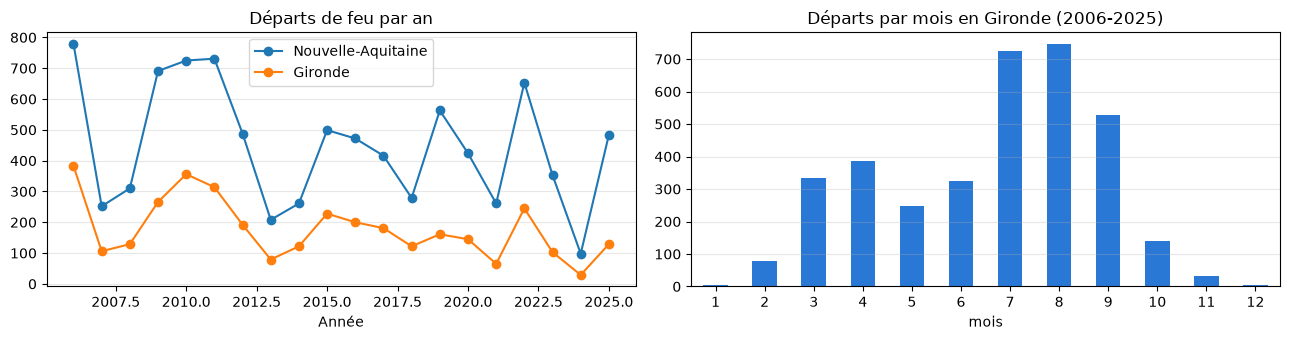

In [139]:
import matplotlib.pyplot as plt

data_na = data_na.assign(surface_ha=data_na['Surface parcourue (m2)'] / 10_000,
                         mois=data_na['Date de première alerte'].dt.month,
                         heure=data_na['Date de première alerte'].dt.hour)
gironde = data_na[data_na['Département'] == '33']

# Volume
print(f"Feux : France {len(data)} · Nouvelle-Aquitaine {len(data_na)} · Gironde {len(gironde)}")
print(f"Part de la Gironde dans la région : {len(gironde) / len(data_na):.0%} des feux, "
      f"{gironde['surface_ha'].sum() / data_na['surface_ha'].sum():.0%} de la surface brûlée")
volume = pd.DataFrame({'Nouvelle-Aquitaine': data_na.groupby('Année').size(),
                       'Gironde': gironde.groupby('Année').size()})

# Ampleur : la plupart des feux sont petits, quelques grands feux font l'essentiel de la surface
print(f"Surface par feu (région) : médiane {data_na['surface_ha'].median():.2f} ha, "
      f"{(data_na['surface_ha'] < 1).mean():.0%} des feux sous 1 ha")
grands = gironde['surface_ha'] >= 100
print(f"Gironde : {grands.sum()} feux de 100 ha ou plus = "
      f"{gironde.loc[grands, 'surface_ha'].sum() / gironde['surface_ha'].sum():.0%} de la surface brûlée")
display(data_na.groupby('Département')['surface_ha']
        .describe(percentiles=[.5, .9, .99]).round(2).rename(columns={'count': 'feux'}))

# Concentration géographique
par_commune = gironde['Code INSEE'].value_counts()
cumul = par_commune.cumsum() / par_commune.sum()
print(f"Gironde : {par_commune.size} communes touchées ; {(cumul < 0.5).sum() + 1} concentrent la moitié des départs, "
      f"{(cumul < 0.8).sum() + 1} en concentrent 80 %")

# Période
print(f"Gironde : {(~gironde['mois'].between(6, 9)).mean():.0%} des départs hors juin-septembre ; "
      f"heure d'alerte la plus fréquente : {gironde['heure'].mode()[0]} h")

# Causes (62 % inconnues dans la région)
display(data_na['Nature'].fillna('Inconnue').value_counts(normalize=True).mul(100).round(1)
        .rename('% des feux (Nouvelle-Aquitaine)'))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
volume.plot(ax=axes[0], marker='o', title='Départs de feu par an')
gironde['mois'].value_counts().sort_index().plot.bar(ax=axes[1], color='#2a78d6', rot=0,
                                                    title='Départs par mois en Gironde (2006-2025)')
for ax in axes:
    ax.grid(axis='y', alpha=.3)
plt.tight_layout()
plt.show()

## Météo des forêts (archives Météo-France, data.gouv.fr)
Niveau de danger 1 à 4 publié pour J+1 et J+2, par département, de juin à septembre depuis 2024. Le jeu de données contient un fichier par saison : le téléchargement (fonction `mdf` de `pipeline/telecharger_sources.py`) les récupère **tous**, puis les enregistre dans `data/meteo_foret_france.csv` (France entière) et `data/meteo_foret_na.csv` (Nouvelle-Aquitaine).

In [140]:
CACHE = 'data/meteo_foret_na.csv'
CACHE_FRANCE = 'data/meteo_foret_france.csv'   # présent seulement si toutes les saisons ont été téléchargées

# Toutes les saisons, via le script de téléchargement (le même code que `python pipeline/telecharger_sources.py`)
if UTILISER_API and not os.path.exists(CACHE_FRANCE):
    from pipeline.telecharger_sources import mdf
    mdf()

if not os.path.exists(CACHE):
    raise FileNotFoundError(f"{CACHE} absent : passer UTILISER_API = True pour le télécharger")

meteo = pd.read_csv(CACHE, dtype={'num_dep': str})
meteo['num_dep'] = meteo['num_dep'].astype(str).str.zfill(2)
meteo['date'] = pd.to_datetime(meteo['date'], utc=True)
meteo = meteo.drop(columns='__id', errors='ignore')

print(meteo.shape, '| du', meteo['date'].min().date(), 'au', meteo['date'].max().date())
meteo.head()

(4452, 6) | du 2024-06-03 au 2026-10-05


,date,num_dep,niveau_j1,niveau_j2,nom_dep,dep_nom
0,2024-06-03 16:00:00+00:00,16,1,1,Charente,NaN
1,2024-06-03 16:00:00+00:00,17,1,1,Charente-Maritime,NaN
2,2024-06-03 16:00:00+00:00,19,1,1,Corrèze,NaN
3,2024-06-03 16:00:00+00:00,23,1,1,Creuse,NaN
4,2024-06-03 16:00:00+00:00,24,1,1,Dordogne,NaN


In [141]:
meteo.describe(include='all')

,date,num_dep,niveau_j1,niveau_j2,nom_dep,dep_nom
count,4452,4452,4452.000000,4452.000000,3012,1440
unique,NaN,12,NaN,NaN,12,12
top,NaN,16,NaN,NaN,Charente,Charente
freq,NaN,371,NaN,NaN,251,120
mean,2025-08-12 18:42:17.619946+00:00,NaN,1.369048,1.321878,NaN,NaN
min,2024-06-03 16:00:00+00:00,NaN,1.000000,1.000000,NaN,NaN
25%,2024-09-03 16:00:00+00:00,NaN,1.000000,1.000000,NaN,NaN
50%,2025-08-07 14:50:04+00:00,NaN,1.000000,1.000000,NaN,NaN
75%,2026-07-05 14:50:04+00:00,NaN,2.000000,2.000000,NaN,NaN
max,2026-10-05 14:50:04+00:00,NaN,4.000000,3.000000,NaN,NaN


### Statistiques descriptives : Météo des forêts
Couverture de chaque saison, répartition des niveaux, stabilité de la prévision entre J+2 et J+1, jours à danger élevé par département.

In [142]:
mdf = meteo.assign(saison=meteo['date'].dt.year)

display(mdf.groupby('saison').agg(emissions=('date', 'nunique'), lignes=('date', 'size'),
                                  premiere_emission=('date', 'min'), derniere_emission=('date', 'max')))

# Répartition des niveaux annoncés pour le lendemain (département x jour)
repartition = pd.crosstab(mdf['saison'], mdf['niveau_j1'], margins=True, margins_name='Total')
repartition.columns = [c if c == 'Total' else f'niveau {c}' for c in repartition.columns]
display(repartition)

# Stabilité : le niveau annoncé à J+2 est-il confirmé le lendemain, à J+1, pour le même jour ?
j1 = mdf.assign(cible=mdf['date'].dt.normalize() + pd.Timedelta(days=1))[['num_dep', 'cible', 'niveau_j1']]
j2 = mdf.assign(cible=mdf['date'].dt.normalize() + pd.Timedelta(days=2))[['num_dep', 'cible', 'niveau_j2']]
paires = j1.merge(j2, on=['num_dep', 'cible'])
print(f"Niveau J+2 confirmé à l'identique en J+1 : {(paires['niveau_j1'] == paires['niveau_j2']).mean():.0%} "
      f"des {len(paires)} paires ; revu à la hausse : {(paires['niveau_j1'] > paires['niveau_j2']).mean():.0%} ; "
      f"à la baisse : {(paires['niveau_j1'] < paires['niveau_j2']).mean():.0%}")

# Jours annoncés « élevé » ou plus, par département et par saison
eleve = (mdf[mdf['niveau_j1'] >= 3]
         .pivot_table(index='num_dep', columns='saison', values='niveau_j1', aggfunc='size', fill_value=0)
         .reindex(dep_na, fill_value=0))
eleve.index.name = 'département (jours niveau ≥ 3)'
display(eleve)

,emissions,lignes,premiere_emission,derniere_emission
saison,,,,
2024,120,1440,2024-06-03 16:00:00+00:00,2024-09-30 16:00:00+00:00
2025,120,1440,2025-06-03 14:50:06+00:00,2025-09-30 14:50:03+00:00
2026,131,1572,2026-05-28 14:50:07+00:00,2026-10-05 14:50:04+00:00


,niveau 1,niveau 2,niveau 3,niveau 4,Total
saison,,,,,
2024,1335,104,1,0,1440
2025,1011,351,78,0,1440
2026,736,645,188,3,1572
Total,3082,1100,267,3,4452


Niveau J+2 confirmé à l'identique en J+1 : 94% des 4416 paires ; revu à la hausse : 6% ; à la baisse : 1%


saison,2024,2025,2026
département (jours niveau ≥ 3),,,
16,0,11,23
17,0,8,25
19,0,2,1
23,0,4,11
24,0,6,12
33,1,4,14
40,0,1,5
47,0,5,13
64,0,0,0


## Référentiel des communes (geo.api.gouv.fr)
Coordonnées du centre, surface (ha) et population de chaque commune. Permet de géolocaliser les incendies de la BDIFF via le code INSEE.

In [143]:
CACHE_COMMUNES = 'data/communes_na.csv'

def telecharger_communes():
    lignes = []
    for dep in dep_na:
        r = requests.get(
            f"https://geo.api.gouv.fr/departements/{dep}/communes",
            params={'fields': 'nom,code,centre,surface,population'}, timeout=60,
        )
        r.raise_for_status()
        for c in r.json():
            lon, lat = c['centre']['coordinates'] if c.get('centre') else (None, None)
            lignes.append({'code_insee': c['code'], 'commune': c['nom'], 'departement': dep,
                           'lat': lat, 'lon': lon,
                           'surface_ha': c.get('surface'), 'population': c.get('population')})
    return pd.DataFrame(lignes)

if os.path.exists(CACHE_COMMUNES):
    communes = pd.read_csv(CACHE_COMMUNES, dtype={'code_insee': str, 'departement': str})
elif UTILISER_API:
    communes = telecharger_communes()
    communes.to_csv(CACHE_COMMUNES, index=False)
else:
    raise FileNotFoundError(f"{CACHE_COMMUNES} absent : passer UTILISER_API = True pour le télécharger")

print(communes.shape)
communes.head()

(4293, 7)


,code_insee,commune,departement,lat,lon,surface_ha,population
0,16001,Abzac,16,46.0999,0.7174,3349.47,518
1,16002,Les Adjots,16,46.0781,0.2028,1130.30,538
2,16003,Agris,16,45.7753,0.3305,1869.86,891
3,16005,Aigre,16,45.8996,0.0252,2379.95,1594
4,16007,Alloue,16,46.0248,0.5297,4665.84,491


In [144]:
# Géolocalisation des incendies de Nouvelle-Aquitaine
feux_na = data_na.merge(communes[['code_insee', 'lat', 'lon', 'surface_ha', 'population']],
                        left_on='Code INSEE', right_on='code_insee', how='left')

# Les communes fusionnées depuis l'incendie n'ont plus de code INSEE actuel
print(f"Incendies non géolocalisés : {feux_na['lat'].isna().mean():.1%}")
feux_na[['Date de première alerte', 'Nom de la commune', 'lat', 'lon', 'Surface parcourue (m2)']].head()

Incendies non géolocalisés : 1.5%


,Date de première alerte,Nom de la commune,lat,lon,Surface parcourue (m2)
0,2006-01-07 17:03:00,Salignac-Eyvigues,44.9470,1.3719,50000
1,2006-01-08 19:05:00,Saint-Paul-de-Serre,45.0794,0.6332,20000
2,2006-02-04 19:20:00,Vouharte,45.8042,0.0777,1000
3,2006-02-05 12:31:00,Salaunes,44.9281,-0.8502,10000
4,2006-02-08 14:59:00,Audenge,44.7133,-0.9533,100


### Statistiques descriptives : communes
Taille des départements, surface et population des communes, qualité du rattachement des feux au référentiel.

In [145]:
display(communes.groupby('departement').agg(
    communes=('code_insee', 'size'),
    surface_moyenne_ha=('surface_ha', 'mean'),
    population_totale=('population', 'sum'),
    population_mediane=('population', 'median'),
).round(0))
display(communes[['surface_ha', 'population']].describe(percentiles=[.5, .9]).round(1))

absents = ~data_na['Code INSEE'].isin(communes['code_insee'])
print(f"Feux de la région dont le code INSEE est absent du référentiel (communes fusionnées) : "
      f"{absents.sum()} ({absents.mean():.1%})")
print(f"Communes touchées au moins une fois depuis 2006 : "
      f"{communes['code_insee'].isin(data_na['Code INSEE']).sum()} sur {len(communes)}")

,communes,surface_moyenne_ha,population_totale,population_mediane
departement,,,,
16,359,1664.0,352683,414.0
17,462,1527.0,672279,652.0
19,277,2129.0,240826,325.0
23,255,2195.0,115527,239.0
24,503,1833.0,417614,388.0
33,534,1944.0,1690493,807.0
40,327,2861.0,433570,583.0
47,319,1689.0,333602,409.0
64,545,1410.0,706564,322.0


,surface_ha,population
count,4293.0,4293.0
mean,1984.3,1432.7
std,1931.4,6131.9
min,2.8,29.0
50%,1454.5,481.0
90%,3791.5,2479.4
max,24828.3,267991.0


Feux de la région dont le code INSEE est absent du référentiel (communes fusionnées) : 137 (1.5%)
Communes touchées au moins une fois depuis 2006 : 1934 sur 4293


## Météo historique quotidienne (Open-Meteo, réanalyse ERA5)
Un point par département (centre moyen de ses communes), de 2006 à 2025.

⚠️ Un seul point par département reste grossier, surtout pour la Gironde et les Landes, qui sont très étendues. On peut l'affiner plus tard avec une grille de points.

ℹ️ L'API gratuite limite le nombre d'appels par heure. Le premier téléchargement peut donc faire une pause, puis reprend tout seul. Chaque département est enregistré dans `data/meteo_quotidienne/`.

In [159]:
DOSSIER_METEO_HIST = 'data/meteo_quotidienne'   # un fichier par département
os.makedirs(DOSSIER_METEO_HIST, exist_ok=True)

VARIABLES_METEO = [
    'temperature_2m_max', 'temperature_2m_mean',
    'precipitation_sum',
    'wind_speed_10m_max', 'wind_gusts_10m_max',
    'relative_humidity_2m_min',
    'et0_fao_evapotranspiration',          # évapotranspiration : dessèchement de la végétation
    'soil_moisture_0_to_7cm_mean',         # humidité du sol en surface
]

# L'API gratuite limite le nombre d'appels par heure. Une requête de 20 ans × 8 variables
# compte pour environ 400 appels, donc les 12 départements peuvent dépasser la limite horaire.
# Chaque département est enregistré séparément : relancer la cellule reprend où elle s'était arrêtée.
def telecharger_meteo_dep(dep, lat, lon, debut='2006-01-01', fin='2025-12-31', essais=8):
    for i in range(1, essais + 1):
        r = requests.get('https://archive-api.open-meteo.com/v1/archive', params={
            'latitude': lat, 'longitude': lon,
            'start_date': debut, 'end_date': fin,
            'daily': ','.join(VARIABLES_METEO), 'timezone': 'Europe/Paris',
        }, timeout=180)
        if r.status_code == 429:   # limite atteinte : on attend
            attente = 600 if 'Hourly' in r.text else 60
            print(f"{dep} : limite Open-Meteo atteinte ({r.json().get('reason')}), attente {attente // 60} min…")
            time.sleep(attente)
            continue
        r.raise_for_status()
        df = pd.DataFrame(r.json()['daily']).rename(columns={'time': 'date'})
        df['departement'] = dep
        return df
    raise RuntimeError(f"Open-Meteo indisponible pour le département {dep}, relancer plus tard")

if UTILISER_API:
    centres = communes.groupby('departement')[['lat', 'lon']].mean()
    for dep, (lat, lon) in centres.iterrows():
        fichier = f'{DOSSIER_METEO_HIST}/{dep}.csv'
        if not os.path.exists(fichier):
            telecharger_meteo_dep(dep, lat, lon).to_csv(fichier, index=False)
            print(f"Département {dep} téléchargé")
            time.sleep(5)

# Chargement des seuls départements déjà présents en .csv
fichiers = [f'{DOSSIER_METEO_HIST}/{dep}.csv' for dep in dep_na
            if os.path.exists(f'{DOSSIER_METEO_HIST}/{dep}.csv')]
if fichiers:
    meteo_hist = pd.concat([pd.read_csv(f, dtype={'departement': str}, parse_dates=['date'])
                            for f in fichiers], ignore_index=True)
    print(meteo_hist.shape, '-', len(fichiers), 'départements sur', len(dep_na))
    display(meteo_hist.head())
else:
    meteo_hist = None
    print(f"Aucune météo historique dans {DOSSIER_METEO_HIST}/ : section ignorée (UTILISER_API = False)")

(87660, 10) - 12 départements sur 12


,date,temperature_2m_max,temperature_2m_mean,precipitation_sum,wind_speed_10m_max,wind_gusts_10m_max,relative_humidity_2m_min,et0_fao_evapotranspiration,soil_moisture_0_to_7cm_mean,departement
0,2006-01-01,9.5,6.0,4.9,23.9,49.3,84,0.57,0.411,16
1,2006-01-02,7.1,5.5,0.0,16.6,37.4,75,0.51,0.394,16
2,2006-01-03,7.3,4.3,0.0,13.0,25.9,65,0.53,0.383,16
3,2006-01-04,4.5,2.8,4.1,12.8,23.4,90,0.22,0.392,16
4,2006-01-05,3.5,0.8,0.0,12.3,24.5,64,0.53,0.384,16


### Statistiques descriptives : météo Open-Meteo
Distribution de chaque variable, climat moyen par mois, variabilité annuelle de la pluie, contrôles de cohérence.

,count,mean,std,min,5%,50%,95%,max
temperature_2m_max,87660.0,17.20,7.42,-5.90,5.60,17.00,29.60,41.70
temperature_2m_mean,87660.0,12.83,6.50,-9.50,2.20,12.70,23.20,33.10
precipitation_sum,87660.0,2.61,5.14,0.00,0.00,0.20,13.20,90.40
wind_speed_10m_max,87660.0,16.25,6.24,2.80,8.20,15.20,28.00,63.10
wind_gusts_10m_max,87660.0,35.19,13.29,8.60,18.00,32.80,60.50,135.70
relative_humidity_2m_min,87660.0,57.68,15.34,8.00,33.00,57.00,84.00,99.00
et0_fao_evapotranspiration,87660.0,2.47,1.66,0.12,0.45,2.15,5.55,9.52
soil_moisture_0_to_7cm_mean,87660.0,0.33,0.08,0.05,0.17,0.35,0.42,0.44


,tmax_moyenne_c,pluie_moyenne_mm_jour,etp_moyenne_mm_jour,humidite_min_moyenne_pct
mois,,,,
1,8.5,3.0,0.7,70.4
2,10.2,2.6,1.2,62.4
3,13.2,2.7,2.0,56.1
4,16.5,2.6,2.9,52.0
5,19.5,3.0,3.5,53.4
6,23.4,2.9,4.2,52.4
7,25.6,1.6,4.5,47.9
8,25.7,1.7,4.1,46.8
9,22.7,2.1,3.0,50.0


Cumul annuel de pluie (mm) par département :


,min,median,max
departement,,,
16,612.0,896.0,1197.0
17,529.0,786.0,1313.0
19,813.0,1209.0,1733.0
23,786.0,963.0,1236.0
24,595.0,877.0,1270.0
33,506.0,791.0,1324.0
40,714.0,950.0,1196.0
47,531.0,758.0,1146.0
64,1095.0,1276.0,1741.0


Contrôles — tmoy > tmax : 0 | rafale < vent : 0 | doublons (département, date) : 0 | jours par département : [7305]


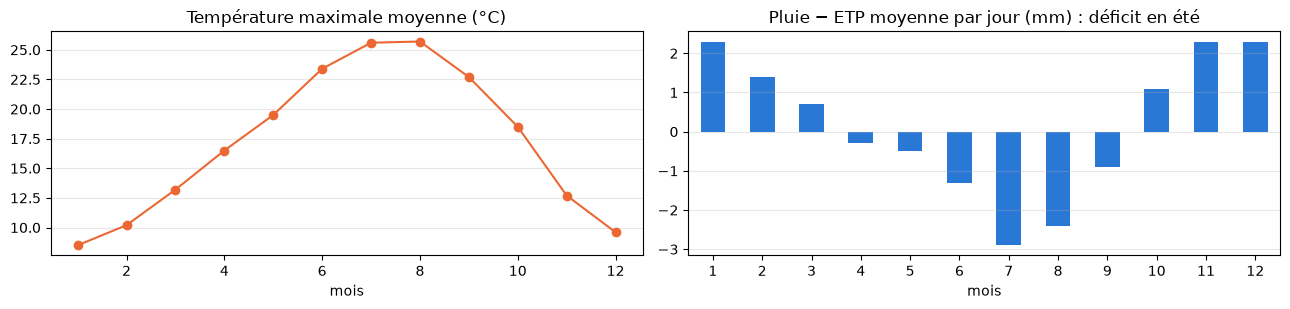

In [147]:
if meteo_hist is not None:
    display(meteo_hist[VARIABLES_METEO].describe(percentiles=[.05, .5, .95]).T.round(2))

    climat = meteo_hist.groupby(meteo_hist['date'].dt.month).agg(
        tmax_moyenne_c=('temperature_2m_max', 'mean'),
        pluie_moyenne_mm_jour=('precipitation_sum', 'mean'),
        etp_moyenne_mm_jour=('et0_fao_evapotranspiration', 'mean'),
        humidite_min_moyenne_pct=('relative_humidity_2m_min', 'mean'),
    ).round(1)
    climat.index.name = 'mois'
    display(climat)

    pluie_an = (meteo_hist.groupby([meteo_hist['date'].dt.year, 'departement'])['precipitation_sum']
                .sum().unstack())
    print("Cumul annuel de pluie (mm) par département :")
    display(pluie_an.agg(['min', 'median', 'max']).T.round(0))

    print("Contrôles — tmoy > tmax :", (meteo_hist['temperature_2m_mean'] > meteo_hist['temperature_2m_max']).sum(),
          "| rafale < vent :", (meteo_hist['wind_gusts_10m_max'] < meteo_hist['wind_speed_10m_max']).sum(),
          "| doublons (département, date) :", meteo_hist.duplicated(['departement', 'date']).sum(),
          "| jours par département :", meteo_hist.groupby('departement').size().unique())

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
    climat['tmax_moyenne_c'].plot(ax=axes[0], marker='o', color='#eb6834', title='Température maximale moyenne (°C)')
    (climat['pluie_moyenne_mm_jour'] - climat['etp_moyenne_mm_jour']).plot.bar(
        ax=axes[1], color='#2a78d6', rot=0, title='Pluie − ETP moyenne par jour (mm) : déficit en été')
    for ax in axes:
        ax.grid(axis='y', alpha=.3)
    plt.tight_layout()
    plt.show()
else:
    print("Pas de météo chargée")

## Détections satellite NASA FIRMS (clé requise)
Points chauds détectés par les satellites MODIS (depuis 2000, résolution 1 km) et VIIRS (depuis 2012, 375 m). C'est la brique « détection » du projet.

1. Obtenir une clé gratuite : https://firms.modaps.eosdis.nasa.gov/api/map_key/
2. La mettre dans un fichier `.env` à la racine du dépôt (à côté de ce notebook), sur une seule ligne :
   ```
   FIRMS_MAP_KEY=votre_cle
   ```
   Le fichier `.env` est exclu de Git par le `.gitignore` : **la clé ne doit jamais apparaître dans le notebook ni dans un commit**. Modèle : `.env.example`.
3. Autre possibilité : définir la variable d'environnement avant de lancer Jupyter (`setx FIRMS_MAP_KEY votre_cle` sous Windows, puis rouvrir le terminal et l'éditeur).

⚠️ FIRMS détecte **tous** les feux, y compris les brûlages agricoles et les sites industriels. Il faut filtrer sur la confiance et croiser avec la BDIFF.

In [ ]:
def lire_cle(nom, fichier='.env'):
    """Variable d'environnement en priorité, sinon ligne NOM=valeur du fichier .env (non versionné)."""
    if os.environ.get(nom):
        return os.environ[nom].strip()
    if os.path.exists(fichier):
        with open(fichier, encoding='utf-8') as f:
            for ligne in f:
                cle, _, valeur = ligne.strip().partition('=')
                if cle.strip() == nom and valeur.strip():
                    return valeur.strip().strip('"').strip("'")
    return None

FIRMS_KEY = lire_cle('FIRMS_MAP_KEY')
print("Clé FIRMS trouvée" if FIRMS_KEY else "Pas de clé FIRMS (fichier .env ou variable FIRMS_MAP_KEY)")
BBOX_NA = '-1.8,42.75,2.65,47.2'          # ouest,sud,est,nord de la Nouvelle-Aquitaine
SOURCE_FIRMS = 'VIIRS_SNPP_SP'            # archive VIIRS (depuis 2012) ; 'MODIS_SP' depuis 2000

def telecharger_firms(annee):
    cache = f'data/firms/{SOURCE_FIRMS}_{annee}.csv'
    if os.path.exists(cache):
        return pd.read_csv(cache)
    os.makedirs('data/firms', exist_ok=True)
    tables = []
    for debut in pd.date_range(f'{annee}-01-01', f'{annee}-12-31', freq='5D'):   # 5 jours max par requête
        url = (f'https://firms.modaps.eosdis.nasa.gov/api/area/csv/'
               f'{FIRMS_KEY}/{SOURCE_FIRMS}/{BBOX_NA}/5/{debut:%Y-%m-%d}')
        r = requests.get(url, timeout=120)
        r.raise_for_status()
        if r.text.strip() and not r.text.startswith('Invalid'):
            tables.append(pd.read_csv(StringIO(r.text)))
    df = pd.concat(tables, ignore_index=True) if tables else pd.DataFrame()
    df.to_csv(cache, index=False)
    return df

if FIRMS_KEY and UTILISER_API:
    firms = pd.concat([telecharger_firms(a) for a in range(2012, 2026)], ignore_index=True)
    firms['acq_date'] = pd.to_datetime(firms['acq_date'])
    print(firms.shape)
    display(firms.head())
else:
    firms = None
    print("Section ignorée (UTILISER_API = False ou pas de clé FIRMS_MAP_KEY)")

Clé FIRMS trouvée


### Statistiques descriptives : FIRMS
Nombre de détections par an, confiance, jour ou nuit, puissance radiative.

In [149]:
if firms is not None and len(firms):
    print(f"{len(firms)} détections, du {firms['acq_date'].min():%d/%m/%Y} au {firms['acq_date'].max():%d/%m/%Y}")
    display(firms.groupby(firms['acq_date'].dt.year).size().rename('détections par an').to_frame().T)
    display(firms['confidence'].value_counts(normalize=True).mul(100).round(1).rename('% par confiance'))
    display(firms['daynight'].value_counts(normalize=True).mul(100).round(1).rename('% jour (D) / nuit (N)'))
    display(firms['frp'].describe(percentiles=[.5, .9, .99]).round(1).rename('puissance radiative (MW)'))
else:
    print("FIRMS non téléchargé : statistiques disponibles après "
          "`python pipeline/telecharger_sources.py --sources firms` (clé dans .env)")

FIRMS non téléchargé : statistiques disponibles après `python pipeline/telecharger_sources.py --sources firms` (clé dans .env)


## Fusion des sources

### Le grain commun : un département × un jour
Pour croiser les sources, il faut un **grain commun**, c'est-à-dire une même définition de « ligne » pour toutes. On a retenu **le département × le jour**, pour deux raisons :
- **c'est le grain le plus fin que partagent l'indice et la météo.** La Météo des forêts n'existe qu'à la maille départementale, et Open-Meteo fournit un point par département. Descendre à la commune obligerait à inventer un niveau de danger et une météo par commune ;
- **les sources plus fines s'y agrègent sans perte de sens.** La BDIFF (un feu dans une commune, à une heure donnée) et FIRMS (un point à une heure UTC) se comptent par département et par jour.

### Le chemin suivi
```
BDIFF ─────────── (commune, heure locale) ── agrégation ─────────────────┐
FIRMS ─────────── (point, heure UTC) ── commune la plus proche ── agrégation ─┤
Open-Meteo ────── (département, jour local) ───────────────────────────────┼──► grille 12 départements × 7 305 jours
Météo des forêts ─ (département, émission UTC) ── recalage au jour J+1 ─────┘
Communes (geo.api) : pont commune → département ; contrôle des codes INSEE ; point météo de chaque département
```

| Étape | Ce qu'on fait | Pourquoi |
|---|---|---|
| 1. Normaliser les clés | Département sur 2 caractères (« 1 » → « 01 ») ; toutes les dates ramenées au **jour local** (Europe/Paris) | Les sources n'écrivent pas les codes de la même façon, et mélangent heure locale et UTC |
| 2. Construire la grille | Tous les départements × tous les jours 2006-2025 | Garder les **jours sans feu** : sans eux, ni taux de feu, ni fausses alertes, ni modèle |
| 3. Joindre Open-Meteo | Jointure à gauche 1:1 sur (département, jour) | Même grain : correspondance attendue de 100 % |
| 4. Joindre la BDIFF agrégée | Compter les feux et sommer les surfaces par (département, jour), puis jointure à gauche ; 0 si aucun feu ; NaN pour le 64 en 2010-2011 | Passer de l'événement au jour ; ne pas confondre « aucun feu » et « aucune donnée » |
| 5. Contrôler par les communes | Vérifier que les codes INSEE des feux existent dans le référentiel | Mesurer ce qui ne pourrait pas être localisé plus finement |
| 6. Joindre la Météo des forêts | Jour concerné = jour local d'émission + 1, puis jointure à gauche 1:1 | Comparer chaque jour au niveau **annoncé la veille**, celui qui déclenche le dispositif |
| 7. Joindre FIRMS (si téléchargé) | Commune la plus proche du point (via le référentiel), son département, le jour local ; comptage ; jointure à gauche | Passer d'un point satellite au même grain que les autres |
| 8. Variables dérivées | Cumuls de pluie, ETP, bilan hydrique, jours sans pluie, calendrier, cible du lendemain | Traduire la météo en sécheresse, ce qui fait réellement brûler |

Chaque jointure est **à gauche sur la grille** et vérifiée **1:1** (`validate='one_to_one'`) : aucune ligne ne peut être dupliquée ou perdue. Le journal de fusion, affiché à la fin, chiffre chaque étape.

In [150]:
# Journal de fusion : une ligne par étape, pour contrôler qu'on ne perd ni ne duplique rien
journal = []
def noter(etape, source, cle, operation, lignes_avant, lignes_apres, correspondance, remarque=''):
    journal.append({'étape': etape, 'source': source, 'clé': cle, 'opération': operation,
                    'lignes avant': lignes_avant, 'lignes après': lignes_apres,
                    'correspondance': f'{correspondance:.1%}' if isinstance(correspondance, float) else correspondance,
                    'remarque': remarque})

# Étape 1 — normaliser les clés : département sur 2 caractères, date = jour local (Europe/Paris)
cle_bdiff = data_na.assign(departement=data_na['Département'].str.zfill(2),
                           date=data_na['Date de première alerte'].dt.normalize())   # heure locale
cle_mdf = meteo.assign(departement=meteo['num_dep'].astype(str).str.zfill(2),
                       date=meteo['date'].dt.tz_convert('Europe/Paris').dt.tz_localize(None).dt.normalize()
                            + pd.Timedelta(days=1))                                  # jour concerné = émission + 1
noter('1', 'toutes', 'département, jour local', 'normalisation', '—', '—', '—',
      'MdF : UTC → Europe/Paris, puis +1 jour (J+1)')

# Étape 2 — la grille : tous les départements × tous les jours, jours sans feu compris
jours = pd.date_range('2006-01-01', '2025-12-31', freq='D')
grille = pd.MultiIndex.from_product([dep_na, jours], names=['departement', 'date']).to_frame(index=False)
noter('2', 'calendrier', 'département × jour', 'produit cartésien', '—', len(grille), '—',
      f'{len(dep_na)} départements × {len(jours)} jours')
print(grille.shape)

(87660, 2)


In [151]:
modele = grille.copy()

# Étape 3 — Open-Meteo : même grain, jointure 1:1
if meteo_hist is not None:
    avant = len(modele)
    modele = modele.merge(meteo_hist, on=['departement', 'date'], how='left', validate='one_to_one')
    noter('3', 'Open-Meteo', '(département, jour)', 'jointure à gauche 1:1', avant, len(modele),
          modele['precipitation_sum'].notna().mean(), 'part des lignes de la grille avec météo')

# Étape 4 — BDIFF : du feu au jour, puis jointure
feux_jour = (cle_bdiff.groupby(['departement', 'date'])
             .agg(nb_feux=('Numéro', 'size'), surface_brulee_ha=('Surface parcourue (m2)', 'sum'))
             .reset_index())
feux_jour['surface_brulee_ha'] /= 10_000
avant = len(modele)
modele = modele.merge(feux_jour, on=['departement', 'date'], how='left', validate='one_to_one', indicator=True)
feux_places = feux_jour.merge(grille, on=['departement', 'date'], how='inner')['nb_feux'].sum()
modele = modele.drop(columns='_merge')
modele[['nb_feux', 'surface_brulee_ha']] = modele[['nb_feux', 'surface_brulee_ha']].fillna(0)
modele['feu'] = (modele['nb_feux'] > 0).astype(int)
manquant = (modele['departement'] == '64') & modele['date'].dt.year.isin([2010, 2011])   # pas de données BDIFF
modele.loc[manquant, ['nb_feux', 'surface_brulee_ha', 'feu']] = np.nan
noter('4', 'BDIFF', '(département, jour d’alerte)', 'agrégation puis jointure à gauche 1:1', avant, len(modele),
      feux_places / len(cle_bdiff), f'{len(cle_bdiff)} feux → {len(feux_jour)} jours avec feu ; 64 en 2010-2011 → NaN')

# Étape 5 — communes : pont et contrôle (pas de jointure à ce grain)
noter('5', 'Communes', 'Code INSEE', 'contrôle du rattachement', len(cle_bdiff), len(cle_bdiff),
      cle_bdiff['Code INSEE'].isin(communes['code_insee']).mean(), 'feux dont la commune existe dans le référentiel')

# Étape 6 — Météo des forêts : niveau annoncé la veille pour le jour concerné
avant = len(modele)
modele = modele.merge(cle_mdf[['departement', 'date', 'niveau_j1']].rename(columns={'niveau_j1': 'niveau_danger'}),
                      on=['departement', 'date'], how='left', validate='one_to_one')
dans_grille = cle_mdf['date'].le(jours.max()).mean()
noter('6', 'Météo des forêts', '(département, jour concerné)', 'recalage J+1 puis jointure à gauche 1:1',
      avant, len(modele), dans_grille,
      'part des prévisions qui tombent dans 2006-2025 (la saison 2026 sort de la grille, faute de BDIFF 2026)')

# Étape 7 — FIRMS : point → commune la plus proche → département, heure UTC → jour local
def commune_la_plus_proche(lat, lon, taille=5000, seuil_deg=0.2):
    # Indice de la commune dont le centre est le plus proche ; -1 si aucune à moins de ~20 km
    centres = np.radians(communes[['lat', 'lon']].to_numpy())
    resultat = []
    for i in range(0, len(lat), taille):
        la = np.radians(lat[i:i + taille])[:, None]
        lo = np.radians(lon[i:i + taille])[:, None]
        d2 = (la - centres[:, 0]) ** 2 + ((lo - centres[:, 1]) * np.cos(la)) ** 2
        k = d2.argmin(axis=1)
        k[d2.min(axis=1) > np.radians(seuil_deg) ** 2] = -1
        resultat.append(k)
    return np.concatenate(resultat) if resultat else np.array([], dtype=int)

if firms is not None and len(firms):
    k = commune_la_plus_proche(firms['latitude'].to_numpy(), firms['longitude'].to_numpy())
    hhmm = firms['acq_time'].astype(int)                     # heure UTC au format HHMM (ex. 1342)
    instant_utc = (firms['acq_date'].dt.tz_localize('UTC')
                   + pd.to_timedelta(hhmm // 100, unit='h') + pd.to_timedelta(hhmm % 100, unit='min'))
    det = firms.assign(departement=np.where(k >= 0, communes['departement'].to_numpy()[np.maximum(k, 0)], None),
                       date=instant_utc.dt.tz_convert('Europe/Paris').dt.tz_localize(None).dt.normalize())
    det_jour = det.dropna(subset=['departement']).groupby(['departement', 'date']).size().rename('nb_detections').reset_index()
    avant = len(modele)
    modele = modele.merge(det_jour, on=['departement', 'date'], how='left', validate='one_to_one')
    modele.loc[modele['date'].dt.year >= 2012, 'nb_detections'] = modele['nb_detections'].fillna(0)
    noter('7', 'FIRMS', '(département, jour local)', 'commune la plus proche, agrégation, jointure à gauche 1:1',
          avant, len(modele), float((k >= 0).mean()), 'détections rattachées à une commune de la région')
else:
    noter('7', 'FIRMS', '(département, jour local)', 'non réalisée', '—', '—', '—', 'données non téléchargées')

display(pd.DataFrame(journal))

,étape,source,clé,opération,lignes avant,lignes après,correspondance,remarque
0,1,toutes,"département, jour local",normalisation,—,—,—,"MdF : UTC → Europe/Paris, puis +1 jour (J+1)"
1,2,calendrier,département × jour,produit cartésien,—,87660,—,12 départements × 7305 jours
2,3,Open-Meteo,"(département, jour)",jointure à gauche 1:1,87660,87660,100.0%,part des lignes de la grille avec météo
3,4,BDIFF,"(département, jour d’alerte)",agrégation puis jointure à gauche 1:1,87660,87660,100.0%,8947 feux → 5526 jours avec feu ; 64 en 2010-2...
4,5,Communes,Code INSEE,contrôle du rattachement,8947,8947,98.5%,feux dont la commune existe dans le référentiel
5,6,Météo des forêts,"(département, jour concerné)",recalage J+1 puis jointure à gauche 1:1,87660,87660,64.7%,part des prévisions qui tombent dans 2006-2025...
6,7,FIRMS,"(département, jour local)",non réalisée,—,—,—,données non téléchargées


In [152]:
# Étape 8 — variables dérivées (par département, dans l'ordre chronologique)
modele = modele.sort_values(['departement', 'date']).reset_index(drop=True)
modele['mois'] = modele['date'].dt.month
modele['jour_annee'] = modele['date'].dt.dayofyear
modele['jour_semaine'] = modele['date'].dt.dayofweek   # 0 = lundi

def jours_sans_pluie(s, seuil=1.0):
    # nombre de jours consécutifs avec moins de 1 mm de pluie
    jour_de_pluie = s >= seuil
    return s.groupby(jour_de_pluie.cumsum()).cumcount()

if meteo_hist is not None:
    g = modele.groupby('departement')
    modele['pluie_7j'] = g['precipitation_sum'].transform(lambda s: s.rolling(7, min_periods=1).sum())
    modele['pluie_30j'] = g['precipitation_sum'].transform(lambda s: s.rolling(30, min_periods=1).sum())
    modele['tmax_moy_7j'] = g['temperature_2m_max'].transform(lambda s: s.rolling(7, min_periods=1).mean())
    modele['et0_cumul_30j'] = g['et0_fao_evapotranspiration'].transform(lambda s: s.rolling(30, min_periods=1).sum())
    modele['bilan_hydrique_30j'] = modele['pluie_30j'] - modele['et0_cumul_30j']
    modele['jours_sans_pluie'] = g['precipitation_sum'].transform(jours_sans_pluie)
    modele.loc[modele['precipitation_sum'].isna(), 'jours_sans_pluie'] = np.nan   # pas de compteur inventé

# Cible J+1 : y a-t-il eu un feu le lendemain dans le département ?
modele['feu_lendemain'] = modele.groupby('departement')['feu'].shift(-1)

modele.to_csv('data/dataset_modele.csv', index=False)
print(modele.shape)
modele.head()

(87660, 24)


,departement,date,temperature_2m_max,temperature_2m_mean,precipitation_sum,wind_speed_10m_max,wind_gusts_10m_max,relative_humidity_2m_min,et0_fao_evapotranspiration,soil_moisture_0_to_7cm_mean,...,mois,jour_annee,jour_semaine,pluie_7j,pluie_30j,tmax_moy_7j,et0_cumul_30j,bilan_hydrique_30j,jours_sans_pluie,feu_lendemain
0,16,2006-01-01,9.5,6.0,4.9,23.9,49.3,84,0.57,0.411,...,1,1,6,4.9,4.9,9.500000,0.57,4.33,0.0,0.0
1,16,2006-01-02,7.1,5.5,0.0,16.6,37.4,75,0.51,0.394,...,1,2,0,4.9,4.9,8.300000,1.08,3.82,1.0,0.0
2,16,2006-01-03,7.3,4.3,0.0,13.0,25.9,65,0.53,0.383,...,1,3,1,4.9,4.9,7.966667,1.61,3.29,2.0,0.0
3,16,2006-01-04,4.5,2.8,4.1,12.8,23.4,90,0.22,0.392,...,1,4,2,9.0,9.0,7.100000,1.83,7.17,0.0,0.0
4,16,2006-01-05,3.5,0.8,0.0,12.3,24.5,64,0.53,0.384,...,1,5,3,9.0,9.0,6.380000,2.36,6.64,1.0,0.0


## Statistiques descriptives sur les données fusionnées

On vérifie d'abord **ce que contient** la table fusionnée (couverture de chaque source, valeurs manquantes, distributions). On mesure ensuite **ce que la fusion apporte** : chaque source enrichit-elle l'explication des départs de feu, ou fait-elle doublon ?

In [153]:
# Couverture : quelle part des lignes porte une information de chaque source, année par année ?
presence = {'Open-Meteo': modele['precipitation_sum'].notna(),
            'BDIFF': modele['feu'].notna(),
            'Météo des forêts': modele['niveau_danger'].notna()}
if 'nb_detections' in modele:
    presence['FIRMS'] = modele['nb_detections'].notna()
couverture = pd.DataFrame(presence).groupby(modele['date'].dt.year).mean().mul(100).round(1)
couverture.index.name = 'année (% des lignes)'
display(couverture.loc[[2006, 2012, 2020, 2023, 2024, 2025]])

complet = pd.DataFrame(presence).all(axis=1)
print(f"Lignes où toutes les sources sont présentes : {complet.sum()} sur {len(modele)} ({complet.mean():.1%}) "
      f"— la Météo des forêts n'existe que de juin à septembre depuis 2024")

# Valeurs manquantes par colonne, avec leur cause
manquantes = modele.isna().mean().mul(100).round(1)
display(manquantes[manquantes > 0].rename('% manquant').to_frame())

display(modele.drop(columns=['date']).describe(percentiles=[.5, .95]).T.round(2))

,Open-Meteo,BDIFF,Météo des forêts
année (% des lignes),,,
2006,100.0,100.0,0.0
2012,100.0,100.0,0.0
2020,100.0,100.0,0.0
2023,100.0,100.0,0.0
2024,100.0,100.0,32.8
2025,100.0,100.0,32.9


Lignes où toutes les sources sont présentes : 2880 sur 87660 (3.3%) — la Météo des forêts n'existe que de juin à septembre depuis 2024


,% manquant
nb_feux,0.8
surface_brulee_ha,0.8
feu,0.8
niveau_danger,96.7
feu_lendemain,0.8


,count,mean,std,min,50%,95%,max
temperature_2m_max,87660.0,17.20,7.42,-5.90,17.00,29.60,41.70
temperature_2m_mean,87660.0,12.83,6.50,-9.50,12.70,23.20,33.10
precipitation_sum,87660.0,2.61,5.14,0.00,0.20,13.20,90.40
wind_speed_10m_max,87660.0,16.25,6.24,2.80,15.20,28.00,63.10
wind_gusts_10m_max,87660.0,35.19,13.29,8.60,32.80,60.50,135.70
relative_humidity_2m_min,87660.0,57.68,15.34,8.00,57.00,84.00,99.00
et0_fao_evapotranspiration,87660.0,2.47,1.66,0.12,2.15,5.55,9.52
soil_moisture_0_to_7cm_mean,87660.0,0.33,0.08,0.05,0.35,0.42,0.44
nb_feux,86930.0,0.10,0.53,0.00,0.00,1.00,31.00
surface_brulee_ha,86930.0,0.56,67.30,0.00,0.00,0.02,18261.00


In [154]:
# Où et quand les feux tombent-ils dans la table fusionnée ?
par_dep = modele.groupby('departement').agg(jours_avec_feu_pct=('feu', 'mean'), feux=('nb_feux', 'sum'),
                                             surface_ha=('surface_brulee_ha', 'sum'))
par_dep['jours_avec_feu_pct'] *= 100
display(par_dep.sort_values('feux', ascending=False).round(1))

par_mois = modele.groupby('mois')['feu'].mean().mul(100).round(1).rename('% de jours avec feu (région)')
display(par_mois.to_frame().T)

,jours_avec_feu_pct,feux,surface_ha
departement,,,
33,24.2,3555.0,35455.6
40,16.2,1905.0,4558.3
24,8.8,1073.0,2011.4
17,7.0,655.0,1008.4
47,5.5,488.0,463.4
16,4.1,366.0,1625.0
19,2.3,220.0,442.8
64,2.3,215.0,1641.1
86,2.5,213.0,783.4


mois,1,2,3,4,5,6,7,8,9,10,11,12
% de jours avec feu (région),0.4,3.5,8.1,10.1,5.5,6.9,13.1,13.5,10.3,3.6,0.9,0.2


### Pertinence de la fusion : ce que la météo ajoute aux feux
Pour chaque variable, on compare les jours **avec** et **sans** départ de feu. L'**AUC** résume ce pouvoir de séparation : 0,5 signifie aucun lien, 1 une séparation parfaite. Elle se calcule sur toute l'année, puis sur l'été seul (juin à septembre). Si la variable garde du pouvoir en été, elle apporte une information que la simple saison ne donne pas.

,moyenne sans feu,moyenne avec feu,AUC année,AUC été,sens
variable,,,,,
relative_humidity_2m_min,58.724,42.136,0.807,0.725,↓ plus de feux quand la valeur baisse
et0_fao_evapotranspiration,2.356,4.107,0.786,0.690,↑ plus de feux quand la valeur monte
soil_moisture_0_to_7cm_mean,0.334,0.254,0.779,0.729,↓ plus de feux quand la valeur baisse
bilan_hydrique_30j,8.387,-59.133,0.771,0.716,↓ plus de feux quand la valeur baisse
temperature_2m_max,16.743,24.049,0.769,0.736,↑ plus de feux quand la valeur monte
tmax_moy_7j,16.810,23.060,0.751,0.741,↑ plus de feux quand la valeur monte
pluie_7j,18.987,7.209,0.718,0.676,↓ plus de feux quand la valeur baisse
pluie_30j,80.046,49.153,0.710,0.684,↓ plus de feux quand la valeur baisse
jours_sans_pluie,2.873,5.995,0.689,0.642,↑ plus de feux quand la valeur monte


,année : % jours avec feu,été : % jours avec feu,jours
jours sans pluie,,,
0,2.8,6.5,32856
1-3,5.1,8.6,28492
4-7,9.7,14.4,14768
8-14,14.1,18.7,8845
15-30,18.5,26.8,2644
> 30,34.5,40.5,55


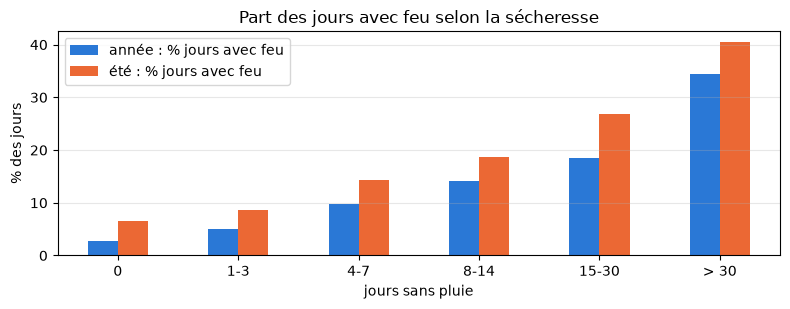

In [155]:
def auc(x, y):
    # Aire sous la courbe ROC d'une seule variable (statistique de Mann-Whitney), sans scikit-learn
    m = x.notna() & y.notna()
    x, y = x[m], y[m].astype(int)
    rangs = x.rank()
    n1, n0 = (y == 1).sum(), (y == 0).sum()
    return (rangs[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

variables = ['temperature_2m_max', 'tmax_moy_7j', 'relative_humidity_2m_min', 'wind_speed_10m_max',
             'precipitation_sum', 'pluie_7j', 'pluie_30j', 'jours_sans_pluie', 'et0_fao_evapotranspiration',
             'bilan_hydrique_30j', 'soil_moisture_0_to_7cm_mean', 'jour_semaine']
ete = modele['mois'].between(6, 9)
lignes = []
for v in variables:
    a_an, a_ete = auc(modele[v], modele['feu']), auc(modele.loc[ete, v], modele.loc[ete, 'feu'])
    lignes.append({'variable': v,
                   'moyenne sans feu': modele.loc[modele['feu'] == 0, v].mean(),
                   'moyenne avec feu': modele.loc[modele['feu'] == 1, v].mean(),
                   'AUC année': max(a_an, 1 - a_an), 'AUC été': max(a_ete, 1 - a_ete),
                   'sens': '↑ plus de feux quand la valeur monte' if a_an > 0.5 else '↓ plus de feux quand la valeur baisse'})
pouvoir = pd.DataFrame(lignes).set_index('variable').sort_values('AUC année', ascending=False).round(3)
display(pouvoir)

# Sécheresse : part des jours avec feu selon le nombre de jours sans pluie, sur l'année et en été
classes = pd.cut(modele['jours_sans_pluie'], [-1, 0, 3, 7, 14, 30, 365],
                 labels=['0', '1-3', '4-7', '8-14', '15-30', '> 30'])
secheresse = pd.DataFrame({
    'année : % jours avec feu': modele.groupby(classes, observed=True)['feu'].mean() * 100,
    'été : % jours avec feu': modele[ete].groupby(classes[ete], observed=True)['feu'].mean() * 100,
    'jours': modele.groupby(classes, observed=True).size(),
}).round(1)
secheresse.index.name = 'jours sans pluie'
display(secheresse)

ax = secheresse[['année : % jours avec feu', 'été : % jours avec feu']].plot.bar(
    rot=0, figsize=(8, 3.2), color=['#2a78d6', '#eb6834'], title='Part des jours avec feu selon la sécheresse')
ax.set_ylabel('% des jours'); ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.show()

### Pertinence de la fusion : l'indice Météo des forêts face aux feux et à la météo
Comparaison possible sur les saisons **2024 et 2025** uniquement : la BDIFF s'arrête fin 2025. On regarde si le niveau annoncé la veille sépare les jours avec et sans feu. On le compare ensuite aux variables météo **sur les mêmes jours**, pour voir si l'indice apporte plus que la météo brute.

In [156]:
fenetre = modele[modele['niveau_danger'].notna() & modele['feu'].notna()]
print(f"{len(fenetre)} jours × départements avec à la fois un niveau annoncé et des données de feux "
      f"({fenetre['date'].dt.year.unique().tolist()})")

par_niveau = fenetre.groupby('niveau_danger').agg(jours=('feu', 'size'), jours_avec_feu_pct=('feu', 'mean'),
                                                  feux=('nb_feux', 'sum'))
par_niveau['jours_avec_feu_pct'] *= 100
par_niveau['part_des_feux_pct'] = par_niveau['feux'] / par_niveau['feux'].sum() * 100
display(par_niveau.round(1))
display(pd.crosstab(fenetre['date'].dt.year, fenetre['niveau_danger'], values=fenetre['feu'], aggfunc='mean')
        .mul(100).round(1).rename_axis(index='saison', columns='% jours avec feu par niveau'))

# Sur la même fenêtre : l'indice sépare-t-il mieux les jours avec feu que la météo brute ?
comparaison = pd.Series({v: max(auc(fenetre[v], fenetre['feu']), 1 - auc(fenetre[v], fenetre['feu']))
                         for v in ['niveau_danger', 'jours_sans_pluie', 'bilan_hydrique_30j', 'tmax_moy_7j',
                                   'relative_humidity_2m_min', 'soil_moisture_0_to_7cm_mean']})
display(comparaison.sort_values(ascending=False).round(3).rename('AUC sur les saisons 2024-2025').to_frame())

# Redondance entre variables explicatives (corrélation de rang de Spearman)
correlations = modele[['niveau_danger', 'tmax_moy_7j', 'relative_humidity_2m_min', 'pluie_30j',
                       'jours_sans_pluie', 'bilan_hydrique_30j', 'soil_moisture_0_to_7cm_mean']].corr(method='spearman')
display(correlations.round(2))

2880 jours × départements avec à la fois un niveau annoncé et des données de feux ([2024, 2025])


,jours,jours_avec_feu_pct,feux,part_des_feux_pct
niveau_danger,,,,
1.0,2346,6.0,174.0,37.9
2.0,455,29.0,229.0,49.9
3.0,79,43.0,56.0,12.2


% jours avec feu par niveau,1.0,2.0,3.0
saison,,,
2024,3.4,13.5,0.0
2025,9.4,33.6,43.6


,AUC sur les saisons 2024-2025
soil_moisture_0_to_7cm_mean,0.808
bilan_hydrique_30j,0.787
tmax_moy_7j,0.761
relative_humidity_2m_min,0.748
niveau_danger,0.702
jours_sans_pluie,0.687


,niveau_danger,tmax_moy_7j,relative_humidity_2m_min,pluie_30j,jours_sans_pluie,bilan_hydrique_30j,soil_moisture_0_to_7cm_mean
niveau_danger,1.00,0.48,-0.55,-0.49,0.49,-0.53,-0.58
tmax_moy_7j,0.48,1.00,-0.53,-0.26,0.13,-0.72,-0.68
relative_humidity_2m_min,-0.55,-0.53,1.00,0.31,-0.44,0.54,0.62
pluie_30j,-0.49,-0.26,0.31,1.00,-0.30,0.79,0.61
jours_sans_pluie,0.49,0.13,-0.44,-0.30,1.00,-0.25,-0.50
bilan_hydrique_30j,-0.53,-0.72,0.54,0.79,-0.25,1.00,0.81
soil_moisture_0_to_7cm_mean,-0.58,-0.68,0.62,0.61,-0.50,0.81,1.00


In [157]:
# FIRMS face aux feux de la BDIFF (si téléchargé)
if 'nb_detections' in modele:
    f = modele[modele['nb_detections'].notna() & modele['feu'].notna()]
    print(f"Jours avec feu BDIFF ayant au moins une détection satellite : {(f.loc[f['feu'] == 1, 'nb_detections'] > 0).mean():.1%}")
    print(f"Jours avec détection satellite sans aucun feu BDIFF : {(f.loc[f['nb_detections'] > 0, 'feu'] == 0).mean():.1%}")
else:
    print("FIRMS non téléchargé : apport de la détection satellite à mesurer après téléchargement")

FIRMS non téléchargé : apport de la détection satellite à mesurer après téléchargement


### Conclusion sur la pertinence de la fusion
Chiffres obtenus le 18/11/2026 sur les données locales (sans FIRMS). Les cellules ci-dessus les recalculent à chaque exécution.

**1. La fusion est sûre : aucune ligne perdue, aucune ligne dupliquée.**
- La grille compte 87 660 lignes (12 départements × 7 305 jours), et chaque jointure est contrôlée en 1:1.
- Les 8 947 feux de la région tombent tous dans la grille (5 526 jours-département avec feu).
- 98,5 % des feux ont une commune présente dans le référentiel. Les 137 restants portent le code d'une commune fusionnée, ce qui n'empêche pas leur rattachement au département.
- La table fusionnée est identique à `gold.ml_departement_jour` de l'entrepôt (dernière section).

**2. La météo apporte une vraie information, au-delà de la saison.**
- La part des jours avec feu passe de 2,8 % après un jour de pluie à 14,1 % après 8 à 14 jours secs, et 18,5 % après 15 à 30 jours secs.
- Les variables les plus discriminantes sont l'humidité minimale (AUC 0,81), l'ETP (0,79), l'humidité du sol (0,78) et le bilan hydrique sur 30 jours (0,77).
- En été seul, ces variables gardent une AUC de 0,69 à 0,74 : elles distinguent les jours à risque même quand la saison ne distingue plus rien. Sans la fusion avec Open-Meteo, cette information serait inaccessible.
- Le vent maximal (0,57, puis 0,51 en été) et le jour de la semaine (0,51) n'apportent presque rien sous cette forme.

**3. L'indice Météo des forêts discrimine les jours, mais moins bien que la météo brute.**
- Sur les saisons 2024 et 2025, la part des jours avec feu croît avec le niveau annoncé : 6 % au niveau 1, 29 % au niveau 2, 43 % au niveau 3.
- Mais 38 % des feux sont partis un jour annoncé « faible ».
- Sur les mêmes jours, l'indice obtient une AUC de 0,70. Plusieurs variables météo font mieux : humidité du sol 0,81, bilan hydrique 0,79, chaleur sur 7 jours 0,76.
- L'indice est corrélé à ces variables (Spearman de 0,48 à 0,58 en valeur absolue), ce qui est logique : il est calculé à partir de la même météo. Il les résume en 4 niveaux et perd une partie de l'information. C'est un argument pour la décision D2 : un seuil peut s'appuyer sur la météo autant que sur le niveau annoncé.

**4. La fusion a des limites.**
- Seules 3,3 % des lignes portent toutes les sources à la fois (juin-septembre 2024 et 2025). L'évaluation de l'indice repose donc sur 2 880 lignes, alors que le modèle de prédiction peut s'appuyer sur 20 ans de météo.
- Un seul point météo par département lisse les écarts locaux, surtout en Gironde et dans les Landes.
- Les feux hors saison (35 % en Gironde) n'ont aucun niveau de danger associé.

**5. Ce qui reste à faire.**
- Ajouter FIRMS pour mesurer l'apport de la détection satellite. Le code de fusion est prêt et testé.
- Ajouter la BDIFF 2026 pour croiser la troisième saison de l'indice.

## Entrepôt de données (architecture médaillon)
`pipeline/pipeline_medaillon.py` reconstruit l'entrepôt DuckDB `warehouse/feux.duckdb` à partir des fichiers de `data/` téléchargés plus haut. Il a trois couches :
- **bronze** : les données brutes, avec leur provenance ;
- **silver** : les données nettoyées et typées, avec des contrôles de qualité ;
- **gold** : le schéma en étoile et la table `ml_departement_jour`.

Voir `docs/entrepot/02-architecture-medaillon.md` et `docs/entrepot/04-modele-uml.md`. Prérequis : `pip install duckdb`.

La cellule suivante vérifie que `gold.ml_departement_jour` contient **les mêmes valeurs** que le tableau `modele` de ce notebook.

In [158]:
%pip install -q duckdb

import subprocess
import sys

import duckdb

resultat = subprocess.run([sys.executable, 'pipeline/pipeline_medaillon.py'], capture_output=True, text=True)
print(resultat.stdout)
if resultat.returncode != 0:
    print(resultat.stderr)
    raise RuntimeError("Le pipeline a échoué")

with duckdb.connect('warehouse/feux.duckdb', read_only=True) as con:
    gold = con.sql("SELECT * FROM gold.ml_departement_jour").df()
gold = gold.rename(columns={'code_dep': 'departement'})
gold['date'] = pd.to_datetime(gold['date'])

# Colonne du notebook -> colonne gold
correspondance = {
    'nb_feux': 'nb_feux', 'surface_brulee_ha': 'surface_brulee_ha', 'feu': 'feu',
    'feu_lendemain': 'feu_lendemain', 'mois': 'mois', 'jour_annee': 'jour_annee',
    'jour_semaine': 'jour_semaine', 'niveau_danger': 'niveau_mdf_j1',
    'precipitation_sum': 'pluie_mm', 'pluie_7j': 'pluie_7j_mm', 'pluie_30j': 'pluie_30j_mm',
    'tmax_moy_7j': 'tmax_moy_7j_c', 'et0_cumul_30j': 'etp_30j_mm',
    'bilan_hydrique_30j': 'bilan_hydrique_30j_mm', 'jours_sans_pluie': 'jours_sans_pluie',
}
comparaison = modele.merge(gold, on=['departement', 'date'], how='outer', suffixes=('_nb', '_gold'),
                           indicator=True)
print("Lignes : notebook", len(modele), "| gold", len(gold),
      "| présentes d'un seul côté", (comparaison['_merge'] != 'both').sum())

lignes = []
for col_nb, col_gold in correspondance.items():
    a = col_nb + '_nb' if col_nb == col_gold else col_nb
    b = col_gold + '_gold' if col_nb == col_gold else col_gold
    if a not in comparaison or b not in comparaison:
        continue
    x = pd.to_numeric(comparaison[a], errors='coerce')
    y = pd.to_numeric(comparaison[b], errors='coerce')
    lignes.append({'notebook': col_nb, 'gold': col_gold,
                   'écart max': float(np.nanmax(np.abs(x - y))) if (x.notna() & y.notna()).any() else 0.0,
                   'NaN différents': int((x.isna() != y.isna()).sum())})
display(pd.DataFrame(lignes))

Note: you may need to restart the kernel to use updated packages.
(bronze.firms_detections : aucun fichier data\firms\*.csv, table vide)
== ContrÃ´les qualitÃ© (silver)
                                                                       regle  nb_defauts  nb_total
                               incendie: surface parcourue nÃ©gative ou nulle           0     52811
                                 incendie: surface forÃªt > surface parcourue           0     52811
                                     incendie: date hors de l'annÃ©e dÃ©clarÃ©e           0     52811
incendie NA: code INSEE absent du rÃ©fÃ©rentiel communes (communes fusionnÃ©es)         137      8947
                                                    incendie: cause inconnue       25620     52811
                                                       mdf: niveau hors 1..4           0      8904
                                        meteo: humiditÃ© relative hors 0..100           0     87660
                              

,notebook,gold,écart max,NaN différents
0,nb_feux,nb_feux,0.000000e+00,0
1,surface_brulee_ha,surface_brulee_ha,2.273737e-13,0
2,feu,feu,0.000000e+00,0
3,feu_lendemain,feu_lendemain,0.000000e+00,0
4,mois,mois,0.000000e+00,0
5,jour_annee,jour_annee,0.000000e+00,0
6,jour_semaine,jour_semaine,0.000000e+00,0
7,niveau_danger,niveau_mdf_j1,0.000000e+00,0
8,precipitation_sum,pluie_mm,0.000000e+00,0
9,pluie_7j,pluie_7j_mm,5.684342e-14,0
